# Weekend 3 (redo): honest ranges

**Question.** At 4 weeks ahead SARIMA is barely better than "same week last year". A hospital doesn't staff to a single number anyway; it staffs *above* its best guess, because understaffing costs more than overstaffing. So the product is a **range**, and a range is only useful if it's **honest**: an 80% range should contain the truth 80% of the time.

**Plan.**
1. One forecast with a range: what a range is.
2. Backtest 388 forecasts and check the range is honest, overall and by season.
3. Experiment: model log(admissions). *(Rejected, see why.)*
4. Fix: build the range from the model's own past mistakes (calibration).
5. The staffing decision: which plan would have cost least?

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')            # SARIMA convergence warnings; counted explicitly below instead

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

URL = ('https://raw.githubusercontent.com/cdcepi/FluSight-forecast-hub/'
       'main/target-data/target-hospital-admissions.csv')
raw = pd.read_csv(URL, parse_dates=['date'])

# one column of weekly US admissions, oldest -> newest, labelled by each week's Saturday
y = raw[raw.location == 'US'].set_index('date')['value'].sort_index().asfreq('W-SAT')

cutoffs = pd.date_range('2024-07-27', '2026-05-30', freq='W-SAT')   # the same 97 dates as weekend 2
WINTER = [11, 12, 1, 2, 3, 4]                                         # flu season, Nov-Apr
print(len(y), 'weeks |', len(cutoffs), 'cutoffs')

243 weeks | 97 cutoffs


## 1. One forecast with a range

Pretend it's **4 Jan 2025**, mid flu season. `.get_forecast()` gives the whole spread, not just the middle line.
- **q10**: only a 10% chance reality comes in lower.
- **q90**: only a 10% chance reality comes in higher. Staffing to q90 = planning for a number that should be beaten 1 week in 10.

                q10     mean      q90   actual
2025-01-11  47451.0  48799.0  50148.0  31828.0
2025-01-18  53686.0  57003.0  60320.0  33676.0
2025-01-25  59151.0  64745.0  70340.0  41400.0
2025-02-01  63264.0  71321.0  79378.0  52520.0


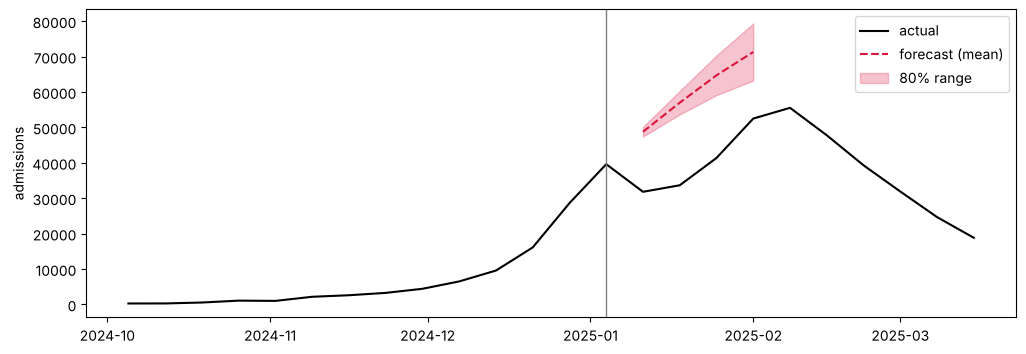

In [2]:
def fit_sarima(series):
    with warnings.catch_warnings():          # statsmodels re-enables its own warnings; silence per fit
        warnings.simplefilter('ignore')
        return SARIMAX(series, order=(1,1,1), seasonal_order=(1,0,0,52),
                   enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

hist = y[:'2025-01-04']
f = fit_sarima(hist).get_forecast(4)
ci = f.conf_int(alpha=0.2)                   # alpha=0.2 -> 80% range
one = pd.DataFrame({'q10': ci.iloc[:, 0], 'mean': f.predicted_mean,
                    'q90': ci.iloc[:, 1], 'actual': y[ci.index]}).round(0)
print(one)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y['2024-10-01':'2025-03-15'], color='black', label='actual')
ax.plot(one['mean'], color='crimson', ls='--', label='forecast (mean)')
ax.fill_between(one.index, one['q10'], one['q90'], color='crimson', alpha=0.25, label='80% range')
ax.axvline(pd.Timestamp('2025-01-04'), color='grey', lw=1)
ax.set_ylabel('admissions'); ax.legend(); plt.show()

**What it shows.**
- The range **widens** with distance: the model is less sure about week 4 than week 1. Good.
- All four actuals fell **below** the range. 4 Jan 2025 was the top of the first hump of the double-peak season; the model extended the climb, reality dipped. Nothing in the past data could signal the turn.
- **Lesson:** the range assumes the model's idea of how the series moves is right. At a turn it isn't, so the model is *confidently wrong*.

## 2. Is the range honest? Backtest 388 forecasts

Refit at each of the 97 cutoffs, forecast 1-4 weeks ahead, keep q10 / mean / q90. Takes about a minute.

In [3]:
def backtest(log=False):
    rows = []
    for c in cutoffs:
        hist = y[:c]
        res = fit_sarima(np.log(hist) if log else hist)
        f = res.get_forecast(4)
        ci = f.conf_int(alpha=0.2)
        back = np.exp if log else (lambda v: v)          # log model: convert back to admissions
        for h in range(4):
            week = f.predicted_mean.index[h]
            rows.append({'cutoff': c, 'horizon': h + 1, 'target_week': week,
                         'q10': back(ci.iloc[h, 0]), 'mean': back(f.predicted_mean.iloc[h]),
                         'q90': back(ci.iloc[h, 1]), 'actual': y[week],
                         'converged': res.mle_retvals['converged']})
    bt = pd.DataFrame(rows)
    bt['winter'] = bt['target_week'].dt.month.isin(WINTER)
    bt['inside'] = (bt['actual'] >= bt['q10']) & (bt['actual'] <= bt['q90'])
    bt['above']  = bt['actual'] > bt['q90']           # reality beat the plan -> understaffed
    bt['below']  = bt['actual'] < bt['q10']
    return bt

bt = backtest()
print(len(bt), 'forecasts |', (~bt.drop_duplicates('cutoff')['converged']).sum(), 'of 97 fits did not converge')

388 forecasts | 0 of 97 fits did not converge


**Floor the forecast.** After a steep post-peak fall, SARIMA can project the decline below zero (e.g. −3,174 admissions forecast for 28 Feb 2026; actual 11,179). Negative admissions are impossible, and they break the ratio calibration in section 4 (actual ÷ ~0 explodes). So the middle line is floored at the **lowest week seen up to the forecast date** (known at the time, so no peeking).

In [4]:
floor = bt['cutoff'].map(lambda c: y[:c].min())
print((bt['mean'] < floor).sum(), 'of', len(bt), 'forecasts were below the floor')
bt['mean'] = np.maximum(bt['mean'], floor)

21 of 388 forecasts were below the floor


In [5]:
print('Overall share inside the 80% range:', round(bt['inside'].mean(), 3), '(target 0.80)')
print('\nBy weeks ahead:'); print(bt.groupby('horizon')['inside'].mean().round(3))
print('\nBy season (True = Nov-Apr):'); print(bt.groupby('winter')[['inside', 'above', 'below']].mean().round(3))

Overall share inside the 80% range: 0.765 (target 0.80)

By weeks ahead:
horizon
1    0.773
2    0.784
3    0.753
4    0.753
Name: inside, dtype: float64

By season (True = Nov-Apr):
        inside  above  below
winter                      
False    1.000  0.000  0.000
True     0.562  0.231  0.207


**What it shows.**
- **Overall ~77% inside**: looks like "slightly overconfident, fine". Misleading.
- **Summer: 100% inside.** The range is so wide it can't miss (it even goes negative, e.g. −4,194 to 4,533 when reality is ~275). Useless.
- **Winter: ~56% inside, and reality beats q90 ~23% of the time** (promised 10%). A hospital staffing to q90 in flu season is understaffed about 1 week in 4.
- **Cause:** SARIMA's range is about the **same width all year**, but real misses are a few hundred admissions in summer and tens of thousands in January. The average hid it, the same way an overall MAE hid Holt-Winters losing at 4 weeks.

## 3. Experiment: model log(admissions)

Idea: on the log scale a fixed-width range is a fixed **percentage**, so the range should scale with the level (and can't go negative).

In [6]:
bt_log = backtest(log=True)
print((~bt_log.drop_duplicates('cutoff')['converged']).sum(), 'of 97 log fits did not converge\n')
print('Coverage by season (True = Nov-Apr):')
print(pd.concat({'original': bt.groupby('winter')[['inside', 'above']].mean(),
                 'log':      bt_log.groupby('winter')[['inside', 'above']].mean()}, axis=1).round(3))

mae = lambda d: (d['mean'] - d['actual']).abs().groupby(d['horizon']).mean()
naive = (y.shift(52)[bt['target_week']].values - bt['actual']).__abs__().groupby(bt['horizon']).mean()
print('\nMAE of the middle line, by weeks ahead:')
print(pd.DataFrame({'naive (same week last year)': naive, 'original': mae(bt), 'log': mae(bt_log)}).round(0))

3 of 97 log fits did not converge

Coverage by season (True = Nov-Apr):
       original           log       
         inside  above inside  above
winter                              
False     1.000  0.000  0.894  0.078
True      0.562  0.231  0.615  0.183

MAE of the middle line, by weeks ahead:
         naive (same week last year)  original     log
horizon                                               
1                             6298.0    1591.0  1655.0
2                             6301.0    3527.0  3697.0
3                             6302.0    4958.0  5862.0
4                             6302.0    5923.0  7780.0


In [7]:
# Why did the log model's MAE get worse? Its worst 4-week misses:
bt_log['err'] = bt_log['mean'] - bt_log['actual']                 # + = forecast too high
bt_log[bt_log['horizon'] == 4].nlargest(5, 'err')[['cutoff', 'target_week', 'mean', 'actual', 'err']].round(0)

,cutoff,target_week,mean,actual,err
299,2025-12-27,2026-01-24,135425.0,16819.0,118606.0
303,2026-01-03,2026-01-31,85542.0,15742.0,69800.0
95,2025-01-04,2025-02-01,110129.0,52520.0,57609.0
111,2025-02-01,2025-03-01,88731.0,31906.0,56825.0
295,2025-12-20,2026-01-17,75779.0,19735.0,56044.0


**What it shows.**
- Ranges improve (summer becomes meaningful, winter improves a little) but winter is still overconfident.
- The **middle line gets much worse at 3-4 weeks**, worse than the naive baseline at 4 weeks.
- **Why:** the log model projects growth as a *percentage*, which compounds (+30%/week for 4 weeks ≈ 2.9×). Forecasts made mid-climb overshoot massively when the curve turns (e.g. 135k projected vs ~17k actual, more than twice the record peak). MAE is in admissions, so those few misses at the turn dominate the average.
- **Decision: rejected.** Keep the original model's middle line and fix the range another way.

## 4. Fix: build the range from past mistakes (calibration)

Stop trusting SARIMA's own uncertainty; use **how wrong it actually was before**. Each past miss as a ratio **actual ÷ forecast**. If 90% of past ratios were below 1.4, then **q90 = forecast × 1.4**. Ratios make the range scale with the level automatically.

**No peeking:** for a forecast made on date *c*, use only past forecasts whose actual was **already known by c** (`target_week <= cutoff`). Using later ones would be *leakage*: great backtest, fails in real life. Need ≥ 20 past examples, otherwise skip.

Two versions: **pooled** (all past mistakes) and **same-season** (only past mistakes from the same season).

In [8]:
bt['ratio'] = bt['actual'] / bt['mean'].clip(lower=1)    # clip: never divide by ~0

def calibrate(bt, same_season, min_past=20):
    q10, q90 = [], []
    for _, row in bt.iterrows():
        mask = (bt['horizon'] == row['horizon']) & (bt['target_week'] <= row['cutoff'])
        if same_season:
            mask &= bt['winter'] == row['winter']
        past = bt.loc[mask, 'ratio']
        if len(past) < min_past:
            q10.append(np.nan); q90.append(np.nan)
        else:
            q10.append(row['mean'] * past.quantile(0.10))
            q90.append(row['mean'] * past.quantile(0.90))
    return np.array(q10), np.array(q90)

bt['pool_q10'], bt['pool_q90'] = calibrate(bt, same_season=False)
bt['seas_q10'], bt['seas_q90'] = calibrate(bt, same_season=True)

def compare(prefix):
    """Calibrated vs original range, scored on the SAME surviving weeks."""
    ok = bt.dropna(subset=[f'{prefix}_q90']).copy()
    ok['cal_inside'] = (ok['actual'] >= ok[f'{prefix}_q10']) & (ok['actual'] <= ok[f'{prefix}_q90'])
    ok['cal_above']  = ok['actual'] > ok[f'{prefix}_q90']
    out = ok.groupby('winter').agg(n=('inside', 'size'), inside_orig=('inside', 'mean'),
                                   cal_inside=('cal_inside', 'mean'),
                                   above_orig=('above', 'mean'), cal_above=('cal_above', 'mean'))
    return out.round(3)

print('POOLED calibration (True = Nov-Apr):'); print(compare('pool'))
print('\nSAME-SEASON calibration:');           print(compare('seas'))

POOLED calibration (True = Nov-Apr):
          n  inside_orig  cal_inside  above_orig  cal_above
winter                                                     
False   134        1.000       0.970       0.000      0.007
True    168        0.571       0.619       0.179      0.137

SAME-SEASON calibration:
          n  inside_orig  cal_inside  above_orig  cal_above
winter                                                     
False    94        1.000       0.787       0.000      0.170
True    122        0.754       0.697       0.131      0.123


**What it shows.**
- **Pooled:** on the same weeks, winter above-q90 drops from ~17.9% to ~13.7% (target 10%). The edge that matters for staffing is now close to honest. But summer is still too wide (~97% inside), because summer ranges are built partly from winter's wild misses.
- **Same-season:** summer coverage ~79%, close to the 80% target, but **lopsided**: reality beats q90 ~17% of the time (promised 10%) and falls below q10 only ~4%. In summer the forecasts run slightly low, and the range doesn't lean the right way. (Before the floor this looked like 89% / 6%, propped up by huge ratios from negative forecasts.) Winter **can't be judged**: needing 20 past *winter* mistakes skips almost all of the 2024-25 winter (the record, double-peak season). The remaining winter weeks are mostly the milder 2025-26 season, where even the original range did fine.
- **Trap avoided:** a method that changes which weeks get scored can't be compared with numbers from other weeks. Hence `*_orig` columns on the same rows.
- **Data limit:** about two winters in the backtest isn't enough to calibrate winter on its own. The weekly snapshot job is collecting exactly the data that fixes this.

## 5. The staffing decision

Each week the hospital picks a **capacity** (admissions it staffs for). Then reality arrives:
- **Overstaffed** (capacity > actual): cost **1** per admission of slack.
- **Understaffed** (actual > capacity): cost **3** per admission of shortfall (agency, overtime, diversions).

The 3 is an assumption, and the unit is "cost points", not dollars: only for ranking strategies.

**Newsvendor rule:** with these costs the best capacity is the **3 / (3 + 1) = 75th percentile**. But only if the percentiles are honest, which is why the ranges were fixed first.

Compared at **4 weeks ahead** (the planning horizon), on the **same weeks** for every strategy.

In [9]:
bt['naive'] = y.shift(52)[bt['target_week']].values          # same week last year

def calibrated_quantile(bt, q, min_past=20):
    """Same-season calibrated percentile (as in section 4) for any q."""
    out = []
    for _, row in bt.iterrows():
        mask = ((bt['horizon'] == row['horizon']) & (bt['target_week'] <= row['cutoff'])
                & (bt['winter'] == row['winter']))
        past = bt.loc[mask, 'ratio']
        out.append(row['mean'] * past.quantile(q) if len(past) >= min_past else np.nan)
    return np.array(out)

bt['seas_q75'] = calibrated_quantile(bt, 0.75)

def cost(actual, capacity, ratio=3):
    over  = np.maximum(capacity - actual, 0)       # unused capacity
    under = np.maximum(actual - capacity, 0)       # shortfall
    return over.sum() + ratio * under.sum()

strategies = {'naive': 'naive', 'mean': 'mean', 'original q90': 'q90',
              'pooled q90': 'pool_q90', 'same-season q90': 'seas_q90', 'same-season q75': 'seas_q75'}

# horizon 4, only weeks where EVERY strategy has a value -> fair comparison
h4 = bt[bt['horizon'] == 4].dropna(subset=list(strategies.values()))
print(len(h4), 'weeks scored:', int(h4['winter'].sum()), 'winter,', int((~h4['winter']).sum()), 'summer\n')

rows = []
for name, col in strategies.items():
    for season, g in [('all', h4), ('winter', h4[h4['winter']]), ('summer', h4[~h4['winter']])]:
        rows.append({'strategy': name, 'season': season,
                     'cost': cost(g['actual'], g[col]),
                     'weeks short': int((g['actual'] > g[col]).sum())})
res = pd.DataFrame(rows)
print('COST (lower is better)')
print(res.pivot(index='strategy', columns='season', values='cost').round(0).sort_values('all'))
print('\nWEEKS SHORT (understaffed)')
print(res.pivot(index='strategy', columns='season', values='weeks short'))

51 weeks scored: 29 winter, 22 summer

COST (lower is better)
season                all    summer    winter
strategy                                     
naive            343771.0   28453.0  315318.0
mean             475907.0    9881.0  466026.0
same-season q75  596397.0   10112.0  586285.0
original q90     649543.0  215633.0  433910.0
pooled q90       662120.0   42831.0  619289.0
same-season q90  811092.0   12089.0  799003.0

WEEKS SHORT (understaffed)
season           all  summer  winter
strategy                            
mean              29      10      19
naive             24      13      11
original q90       4       0       4
pooled q90         5       0       5
same-season q75   15       8       7
same-season q90   10       6       4


**Naive "wins" in winter here. Don't believe it yet.** Only 51 weeks are scored: the same-season rule skipped most of the 2024-25 winter, so "winter" is mostly **2025-26**. Copying last year for 2025-26 meant copying **2024-25**, the record season: bigger and later. So naive overstaffed most weeks (the cheap mistake, cost 1) and was rarely short. Luck, not skill.

**Check:** naive vs mean on **all** 4-week forecasts, both winters included.

In [10]:
all_h4 = bt[bt['horizon'] == 4]
for season, g in [('winter', all_h4[all_h4['winter']]), ('summer', all_h4[~all_h4['winter']])]:
    print(f"{season}: {len(g)} weeks | naive {cost(g['actual'], g['naive']):>11,.0f} | mean {cost(g['actual'], g['mean']):>11,.0f}")

winter: 52 weeks | naive   1,234,498 | mean   1,084,087
summer: 45 weeks | naive      71,701 | mean      19,617


**What it shows.**
- **Naive's win was sample luck.** With the 2024-25 winter included (a season *bigger* than the one before), the mean beats naive in winter and summer. Third time today the result depended on which weeks were scored.
- **Summer: calibration's clear win.** Same-season ranges cut summer overstaffing cost by ~94% vs the original q90 (215k -> 12k).
- **Calibrated percentiles are roughly honest about shortfalls.** Winter weeks short (of 29): same-season q90 4 (~14%, promised 10%), q75 7 (~24%, promised 25%).
- **But in winter the calibrated percentiles cost more than the plain mean** (q75 586k, q90 799k vs mean 466k), while the original q90, a smaller margin, beat the mean (434k). Why, if q75 is honest? It's honest *on average across winter*, but the model's errors depend on the **phase of the epidemic**: on the climb the mean is too low (a margin helps), but forecasts made **at the top of the curve** are already far too high. Calibrated margins are proportional to the forecast, so the biggest margins land on exactly those overshooting forecasts, in the biggest-number weeks. The newsvendor rule assumes uncertainty is the same in every situation; here it isn't.
- **Caveat:** 29 winter weeks, mostly one season. Treat the winter ranking as a lead to test, not a result.

## 6. Summary

| Step | Finding |
|---|---|
| Original SARIMA range | ~77% coverage overall, but 100% summer / ~56% winter; winter q90 beaten ~23% (promised 10%) |
| Cause | Range has ~constant width; real errors scale with the level |
| Log SARIMA | Ranges somewhat better, but 4-wk MAE +30% (compounding overshoot at turns) -> **rejected** |
| Floor | 21 of 388 forecasts went below zero after steep falls; floored at the lowest week seen so far |
| Pooled calibration | Winter q90 beaten ~13.7% vs ~17.9% for the original on the same weeks; summer still too wide |
| Same-season calibration | Summer ~79% coverage (near target) but lopsided: q90 beaten ~17%; winter untestable with ~2 winters of history |
| Staffing (3:1, 4 weeks) | Calibration cuts summer waste ~94%; in winter calibrated margins cost more than the plain mean (29 weeks, ~1 season), because forecasts made at the top of the curve overshoot |

**In one paragraph.** SARIMA's own 80% interval looked fine overall (77%) but was 100% in summer and 56% in flu season, because its width is constant while errors scale with the level. Log-transforming improved coverage but made 4-week accuracy 30% worse through compounding overshoot. Calibrating intervals from the model's own past errors, without leakage, made winter shortfall rates roughly honest and cut summer overstaffing cost by ~94%. But in flu season the calibrated percentiles cost more than the plain mean at a 3:1 cost ratio, because the model's errors depend on the phase of the epidemic: it under-forecasts the climb and overshoots when forecasting from the top of the curve. With about two winters of history (and only ~one in the staffing comparison) this is a finding to confirm as the vintage archive grows, not a final answer.

**Next idea:** calibrate by **phase** instead of by season, which targets the cause directly. First exploration in section 7.

## 7. Toward phase-based calibration (exploration)

Is the model's error different on the way up vs the way down? Phase must be known on the forecast date, so **rising = last week higher than the week before**.

In [11]:
bt['rising'] = y[bt['cutoff']].values > y[bt['cutoff'] - pd.Timedelta(weeks=1)].values
h4 = bt[bt['horizon'] == 4]
print('Examples per group:'); print(h4.groupby(['winter', 'rising']).size())
print('\nactual / forecast ratio, 10th / 50th / 90th percentile:')
print(h4.groupby(['winter', 'rising'])['ratio'].quantile([0.10, 0.50, 0.90]).unstack().round(2))

Examples per group:
winter  rising
False   False     34
        True      11
True    False     20
        True      32
dtype: int64

actual / forecast ratio, 10th / 50th / 90th percentile:
                0.1   0.5   0.9
winter rising                  
False  False   0.71  0.91  1.60
       True    0.60  0.93  1.08
True   False   0.39  0.97  6.44
       True    0.52  1.54  3.12


**What it shows.**
- **Winter, rising:** median 1.54: on the climb, reality typically lands ~50% above the 4-week forecast. But the spread runs from ~0.5 to ~3: the "rising" group also contains forecasts made **at the top**, which overshoot. On the forecast date, the week before a peak looks like any other climbing week.
- **Winter, falling:** median ~0.97, roughly on target, with an occasional collapse: the floor removes impossible forecasts, not absurd ones (a 223 forecast in February, when admissions were ~20,000, still gives a ratio of 50).
- **Next:** a better phase signal. Before a peak, growth usually **slows** (+8k, +5k, +2k). A "decelerating" label might separate the climb from the top.